2025.2.24 - finished the first version\
2025.2.25 - added new things\
2025.2.27 - debugging\
2025.11.6 - debugging, only pick .tif files\
2026.7.29 - implementing new feature - assuming an equal displacement during the stage movement than that in the last frame of a kymo\
2026.8.23 - implementing new feature - Correct the instantaneous velocity based on embryo surface curvature

## Inputs from you

In [1]:
kymo_to_be_stitched = 'kymo_mains_for_contours' # the name of the folder, where all the kymos are saved
contours = 'contours'
i_vel_skip = 1 # step size for the velocity calculations
pixel_size = 0.34 # microns
time_intervals = [300, 300, 300, 300] #seconds
time_window_to_calculate_variance = 0 #min

## The code

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math, scipy, skimage, os
import matplotlib as mpl
import seaborn as sns

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['font.size'] = 12
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['pdf.fonttype'] = 42


## Load kymographs

(13, 1023)


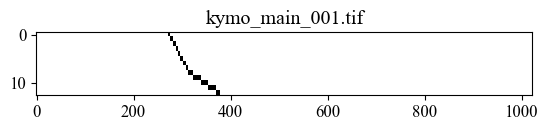

(17, 1022)


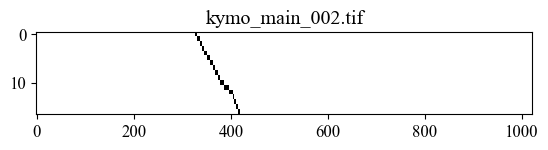

(7, 1022)


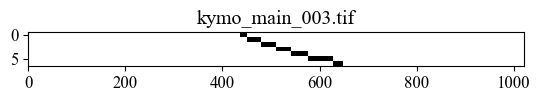

(3, 1020)


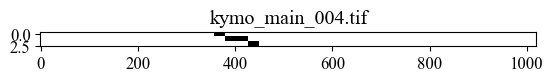

In [3]:
kymo_raw_images_filenames = os.listdir(kymo_to_be_stitched)
kymo_raw_images_filenames.sort()
kymo_raw_images_filenames = [kymo_raw_images_filename for kymo_raw_images_filename in kymo_raw_images_filenames if '.tif' in kymo_raw_images_filename]
kymo_raw_image_num = len(kymo_raw_images_filenames)
kymo_raw_images = [skimage.io.imread(kymo_to_be_stitched + '//' + kymo_raw_images_filename) for kymo_raw_images_filename in kymo_raw_images_filenames]

for i in range(kymo_raw_image_num):
    fig, ax = plt.subplots()
    ax.set_title(kymo_raw_images_filenames[i])
    ax.imshow(kymo_raw_images[i], cmap='Greys', interpolation='none', aspect=10)
    print(kymo_raw_images[i].shape)
    plt.show()

## Load the contours

In [4]:
contours_filenames = os.listdir(contours)
contours_filenames.sort()
contours_filenames = [contours_filename for contours_filename in contours_filenames if '.tif' in contours_filename]
contour_images = [skimage.io.imread(contours + '//' + contours_filename) for contours_filename in contours_filenames]

# check if the contours have the same y-axis length as kymographs
# if not, then compensate for kymographs

for i in range(kymo_raw_image_num):
    print(kymo_raw_images_filenames[i])
    a = kymo_raw_images[i].shape[1] == contour_images[i].shape[0]
    print(a)

    if not a:
        if kymo_raw_images[i].shape[1] < contour_images[i].shape[0]:
            a = contour_images[i][0:kymo_raw_images[i].shape[1]]
        else:
            a = np.vstack([contour_images[i], np.zeros((kymo_raw_images[i].shape[1] - contour_images[i].shape[0], contour_images[i].shape[1]))])
        contour_images[i] = a

kymo_main_001.tif
True
kymo_main_002.tif
False
kymo_main_003.tif
True
kymo_main_004.tif
True


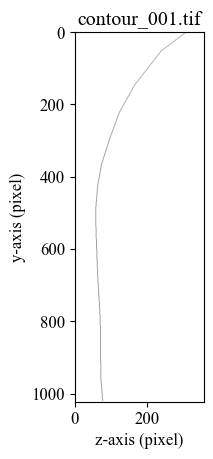

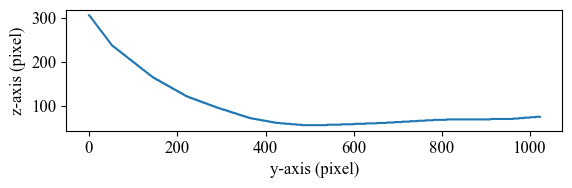

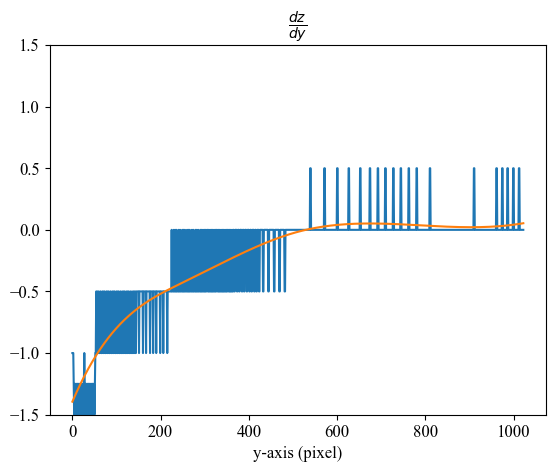

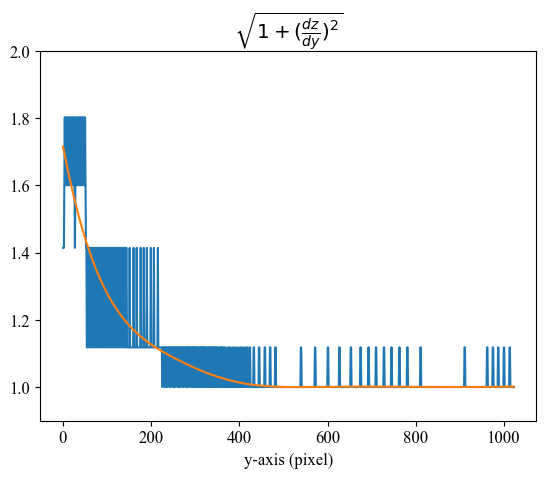

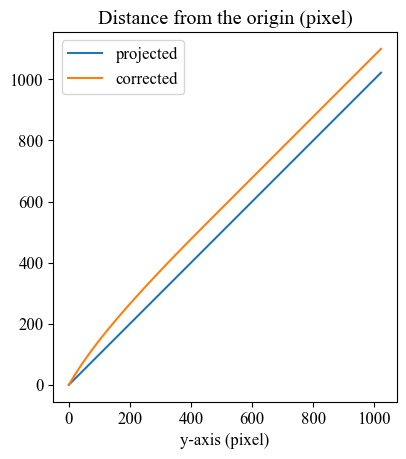

real length: 1100.0616089864748


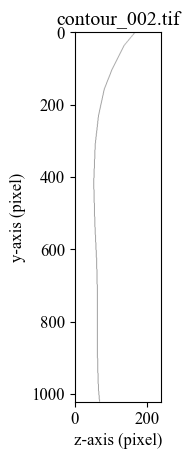

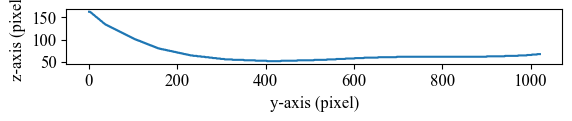

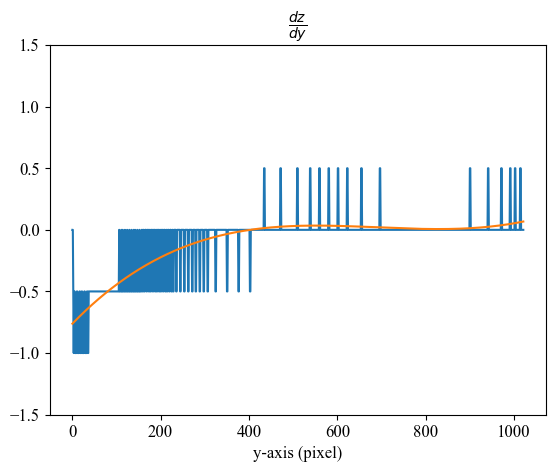

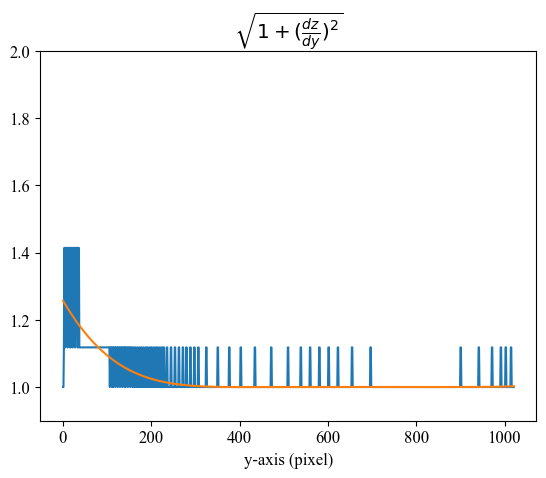

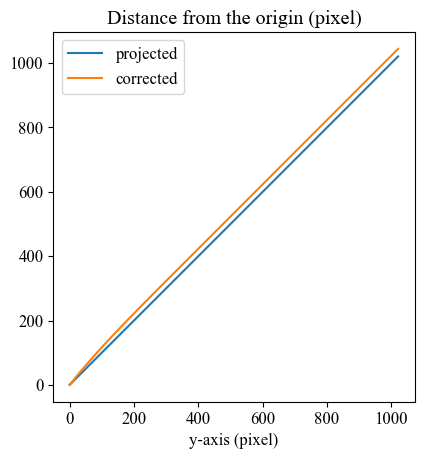

real length: 1044.3921516430146


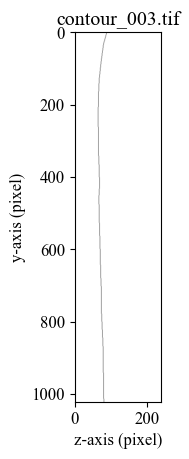

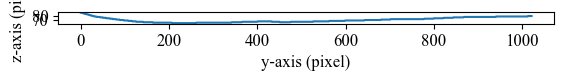

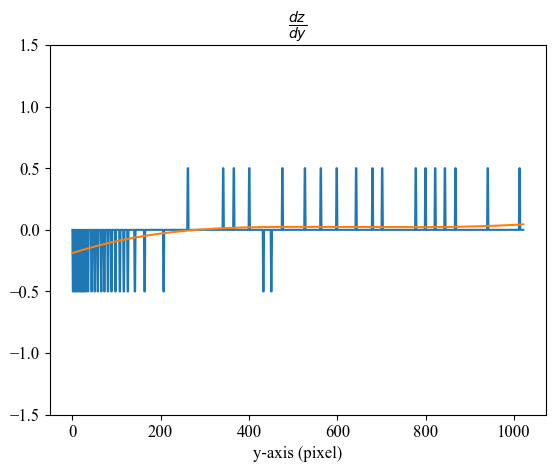

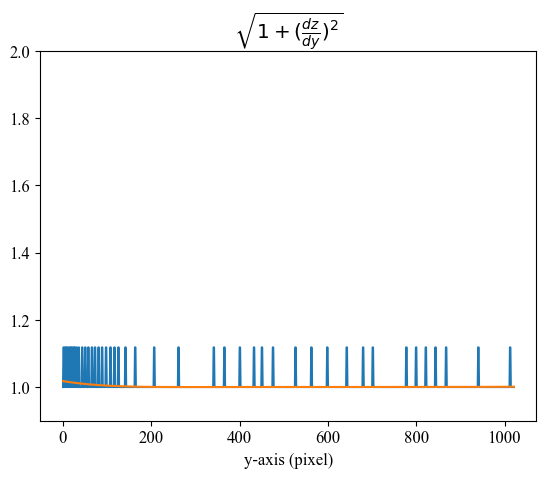

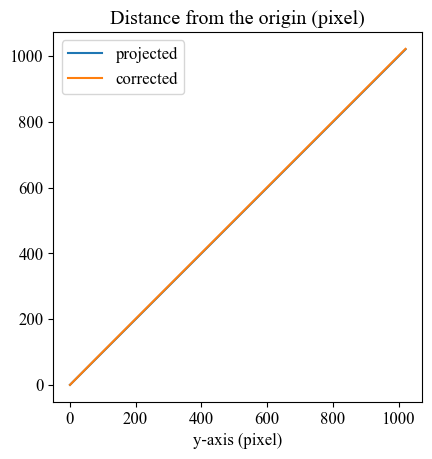

real length: 1022.3864166960656


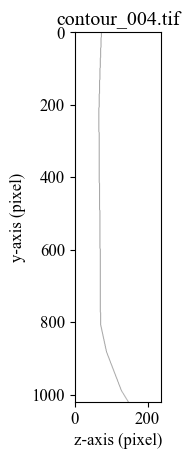

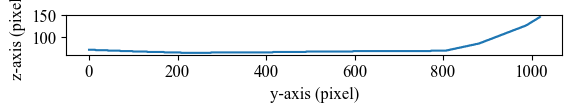

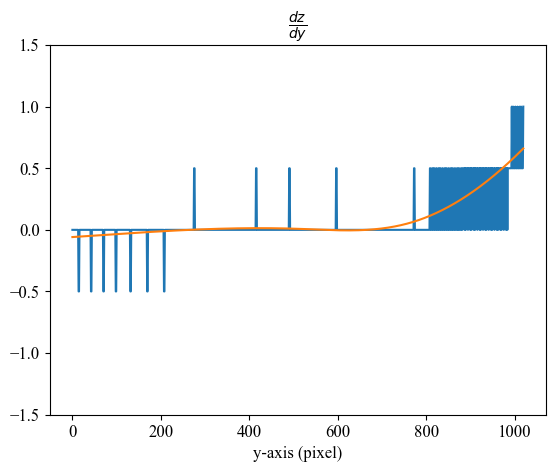

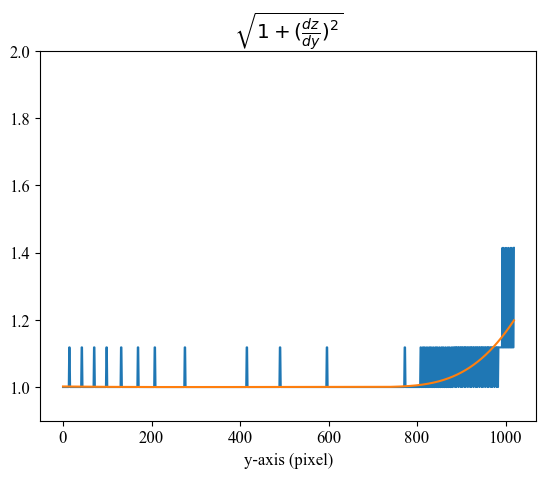

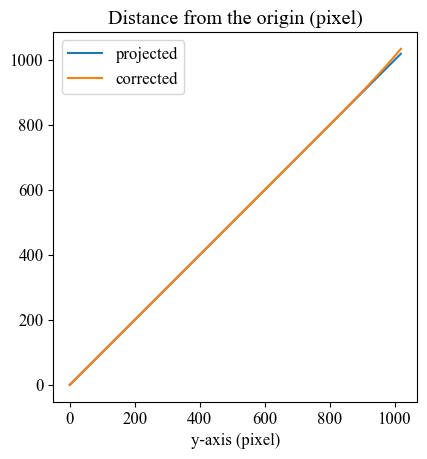

real length: 1034.1213842769048


In [19]:
real_distances = []
height_maps = []

for i in range(kymo_raw_image_num):

    fig, ax = plt.subplots()
    ax.set_title(contours_filenames[i])
    ax.imshow(contour_images[i], cmap='Greys', interpolation='bilinear', aspect=1)
    ax.set_xlabel('z-axis (pixel)')
    ax.set_ylabel('y-axis (pixel)')
    plt.show()

    contour = contour_images[i]
    ys, zs = contour.shape

    height_map = []
    for y in range(ys):
        z_slice = contour[y]
        if np.any(z_slice!=0):
            height = np.mean(np.where(z_slice))
            height_map.append(height)
        else:
            # height_map.append(np.nan)
            height_map.append(np.nan)

    yaxis = np.arange(ys)
    height_map = np.array(height_map)
    height_maps.append(height_map)

    # remove np.nan
    if np.any(np.isnan(height_map)):
        a = height_map
        a_begin, a_end = np.where(~np.isnan(a))[0][[0, -1]]
        a[:a_begin] = a[a_begin]
        a[a_end+1:] = a[a_end]
        height_map = a

    spl = scipy.interpolate.UnivariateSpline(yaxis, height_map, k=4, s=ys, check_finite=False)  # s controls smoothing
    dy = spl.derivative()(yaxis)

    fig, ax = plt.subplots()
    ax.plot(height_map)
    ax.set_aspect('equal')
    ax.set_ylabel('z-axis (pixel)')
    ax.set_xlabel('y-axis (pixel)')
    plt.show()

    fig, ax = plt.subplots()
    ax.plot(np.gradient(height_map))
    ax.plot(dy)
    ax.set_xlabel('y-axis (pixel)')
    ax.set_title(r'$\frac{dz}{dy}$')
    ax.set_ylim(-1.5, 1.5)
    plt.show()

    fig, ax = plt.subplots()
    ax.plot(np.sqrt(1 +np.abs(np.gradient(height_map))**2))
    ax.plot(np.sqrt(1 + np.abs(dy)**2))
    ax.set_xlabel('y-axis (pixel)')
    ax.set_title(r'$ \sqrt{1 + (\frac{dz}{dy})^2}$')
    ax.set_ylim(0.9, 2)
    plt.show()

    correction_coefficient = np.sqrt(1 + np.abs(dy)**2)

    real_distance = scipy.integrate.cumulative_trapezoid(correction_coefficient, yaxis, initial=0)
    real_distances.append(real_distance)

    fig, ax = plt.subplots()
    ax.plot(yaxis, yaxis, label='projected')
    ax.plot(yaxis, real_distance, label='corrected')
    ax.set_aspect('equal')
    ax.set_xlabel('y-axis (pixel)')
    ax.set_title('Distance from the origin (pixel)')
    plt.legend()
    plt.show()

    print('real length:', real_distance[-1])

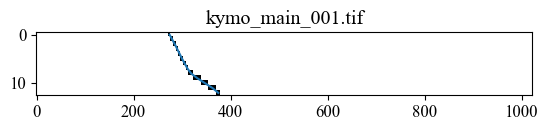

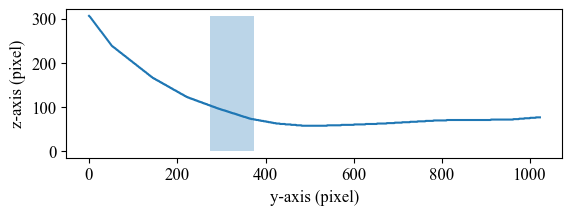

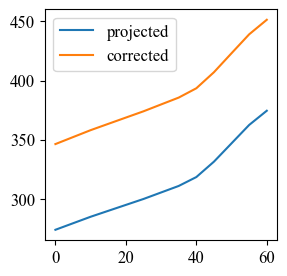

kymo_main_001.tif
duration 60.0 sec
start position 274.0
end position 374.5


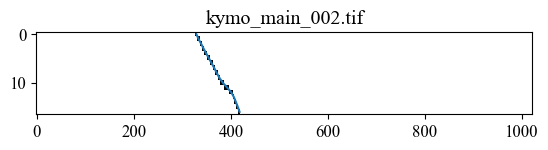

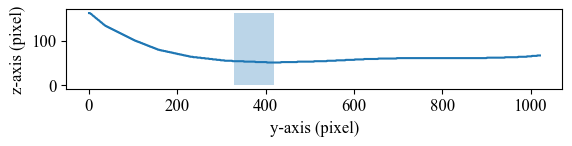

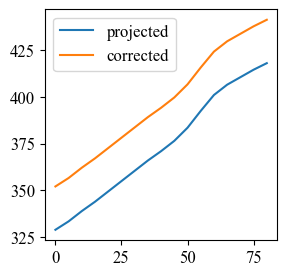

kymo_main_002.tif
duration 80.0 sec
start position 329.0
end position 418.0


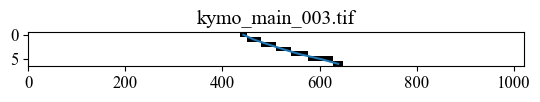

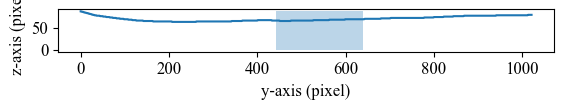

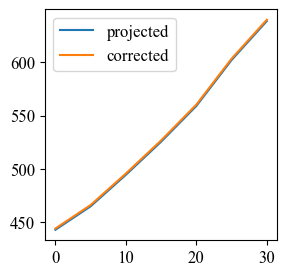

kymo_main_003.tif
duration 30.0 sec
start position 443.0
end position 638.5


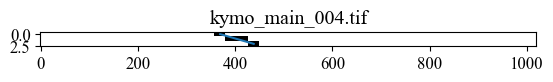

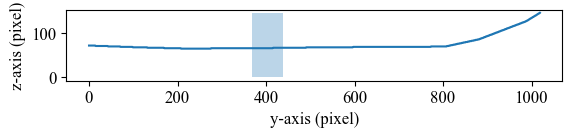

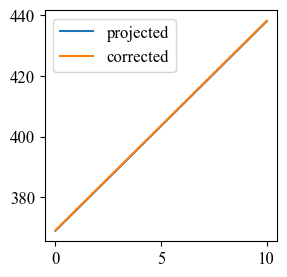

kymo_main_004.tif
duration 10.0 sec
start position 369.0
end position 438.0


In [22]:
trajectories = []

for i in range(kymo_raw_image_num):
# for i in [0]:
    kymo = kymo_raw_images[i]
    real_distance = real_distances[i]
    height_map = height_maps[i]

    fs, ys = kymo.shape
    yaxis = np.arange(ys)

    trajectory = []
    for f in range(fs):
        y_slice = kymo[f]
        if np.any(y_slice!=0):
            y_position = np.mean(np.where(y_slice))
            trajectory.append(y_position)
        else:
            fs=f
            break
            
    trajectory = np.array(trajectory)
    real_displacement = np.interp(trajectory, yaxis, real_distance)

    frame = np.arange(fs)
    time = np.arange(fs) * time_intervals[i] /60

    fig, ax = plt.subplots()
    ax.set_title(kymo_raw_images_filenames[i])
    ax.imshow(kymo_raw_images[i], cmap='Greys', interpolation='none', aspect=10)
    ax.plot(trajectory, np.arange(fs))
    plt.show()

    fig, ax = plt.subplots()
    ax.plot(height_map)
    ax.fill_betweenx(y=[0, height_map.max()], x1=trajectory[0], x2=trajectory[-1], alpha=.3, ec='none')
    ax.set_aspect('equal')
    ax.set_ylabel('z-axis (pixel)')
    ax.set_xlabel('y-axis (pixel)')
    plt.show()
    
    fig, ax = plt.subplots(figsize=[3,3])
    # ax.set_title(kymo_raw_images_filenames[i])
    # ax.imshow(kymo_raw_images[i], cmap='Greys')
    ax.plot(time, trajectory, label='projected')
    ax.plot(time, real_displacement, label='corrected')
    plt.legend()
    plt.show()

    print(kymo_raw_images_filenames[i])
    print('duration', time[-1] , 'sec')
    print('start position', trajectory[0])
    print('end position', trajectory[-1])

    trajectory = {'kymo_subset':kymo_raw_images_filenames[i],
                  'frame':frame,
                  'time':time,
                  'trajectory':trajectory,
                  'trajectory_corrected':real_displacement}
    trajectories.append(trajectory)

## Stitch all the fragments

delta ys: [  0.   57.5  36.  342. ]
delta ys corrected: [  0.         111.41883615 111.90723434 419.02073476]


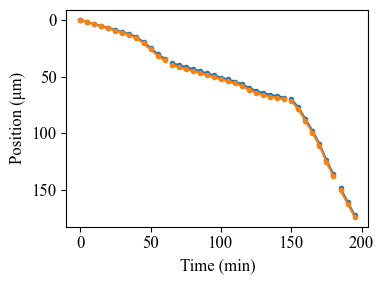

In [7]:
# max proj.

delta_ys = [0,]
delta_ys_corrected = [0, ]
delta_ts = [0,]

for i in range(1, kymo_raw_image_num):
    delta_y = trajectories[i-1]['trajectory'][-1] - trajectories[i]['trajectory'][0]
    delta_y += (trajectories[i-1]['trajectory'][-1] - trajectories[i-1]['trajectory'][-2])

    delta_y_corrected = trajectories[i-1]['trajectory_corrected'][-1] - trajectories[i]['trajectory_corrected'][0]
    delta_y_corrected += (trajectories[i-1]['trajectory_corrected'][-1] - trajectories[i-1]['trajectory_corrected'][-2])

    delta_t = trajectories[i-1]['time'][-1] - trajectories[i]['time'][0]
    delta_t += (time_intervals[i-1] /60)

    delta_ys.append(delta_y)
    delta_ys_corrected.append(delta_y_corrected)
    delta_ts.append(delta_t)

delta_ys, delta_ys_corrected, delta_ts = np.array(delta_ys), np.array(delta_ys_corrected), np.array(delta_ts)

for i in range(1, kymo_raw_image_num):
    delta_ys[i] += delta_ys[i-1]
    delta_ys_corrected[i] += delta_ys_corrected[i-1]
    delta_ts[i] += delta_ts[i-1]

print('delta ys:', delta_ys)
print('delta ys corrected:', delta_ys_corrected)

trajectories_stitched = []
start_point = trajectories[0]['trajectory'][0] + delta_ys[0]
start_point_corrected = trajectories[0]['trajectory_corrected'][0] + delta_ys_corrected[0]

fig, ax = plt.subplots(figsize=[4,3])
for i in range(0, kymo_raw_image_num):
    trajectory = trajectories[i]['trajectory'] + delta_ys[i]
    trajectory_corrected = trajectories[i]['trajectory_corrected'] + delta_ys_corrected[i]

    time = trajectories[i]['time'] + delta_ts[i]
    
    ax.plot(time, (trajectory - start_point) * pixel_size, color = 'tab:blue')
    ax.plot(time, (trajectory - start_point) * pixel_size, 'o', color = 'tab:blue', markersize=3)

    ax.plot(time, (trajectory_corrected - start_point_corrected) * pixel_size, color = 'tab:orange')
    ax.plot(time, (trajectory_corrected - start_point_corrected) * pixel_size, 'o', color = 'tab:orange', markersize=3)
    
    trajectory_stitched = {'kymo_subset':kymo_raw_images_filenames[i],
                           'time':time,
                           'trajectory':trajectory,
                           'trajectory_corrected':trajectory_corrected}
    trajectories_stitched.append(trajectory_stitched)
    
ax.invert_yaxis()
ax.set_xlabel('Time (min)')
ax.set_ylabel('Position (\u03BCm)')
plt.tight_layout()
plt.savefig('displacement_with_colors.pdf')
plt.show()

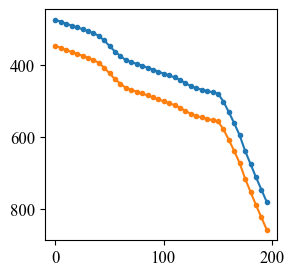

,frame,time,kymo_num,y_coord_original,y_coord,position,displacement_per_frame,y_coord_corrected_original,y_coord_corrected,position_corrected,displacement_per_frame_corrected
0,0,0.0,1,274.0,274.0,0.00,0.0,346.351295,346.351295,0.000000,0.000000
1,1,5.0,1,279.5,279.5,1.87,5.5,352.237737,352.237737,2.001390,5.886442
2,2,10.0,1,285.0,285.0,3.74,5.5,358.105311,358.105311,3.996365,5.867574
3,3,15.0,1,290.0,290.0,5.44,5.0,363.423202,363.423202,5.804448,5.317891
4,4,20.0,1,295.0,295.0,7.14,5.0,368.725974,368.725974,7.607391,5.302772
5,5,25.0,1,300.0,300.0,8.84,5.0,374.013938,374.013938,9.405299,5.287964
6,6,30.0,1,305.5,305.5,10.71,5.5,379.813911,379.813911,11.377289,5.799973
7,7,35.0,1,311.0,311.0,12.58,5.5,385.596945,385.596945,13.343521,5.783034
8,8,40.0,1,318.5,318.5,15.13,7.5,393.456055,393.456055,16.015618,7.859109
9,9,45.0,1,331.5,331.5,19.55,13.0,407.009065,407.009065,20.623642,13.553011


In [8]:
time_final = np.concatenate([trajectories_stitched[i]['time'] for i in range(0, kymo_raw_image_num)])
trajectory_final = np.concatenate([trajectories_stitched[i]['trajectory'] for i in range(0, kymo_raw_image_num)])
trajectory_corrected_final = np.concatenate([trajectories_stitched[i]['trajectory_corrected'] for i in range(0, kymo_raw_image_num)])

displacement_final = (trajectory_final - trajectory_final[0]) * pixel_size
displacement_corrected_final = (trajectory_corrected_final - trajectory_corrected_final[0]) * pixel_size

frame_final = np.concatenate([trajectories[i]['frame'] for i in range(0, kymo_raw_image_num)])
y_coord_original = np.concatenate([trajectories[i]['trajectory'] for i in range(0, kymo_raw_image_num)])
y_coord_corrected_original = np.concatenate([trajectories[i]['trajectory_corrected'] for i in range(0, kymo_raw_image_num)])

fig, ax = plt.subplots(figsize=[3,3])
ax.plot(time_final, trajectory_final, color='tab:blue')
ax.plot(time_final, trajectory_final, 'o', color='tab:blue', ms=3)

ax.plot(time_final, trajectory_corrected_final, color='tab:orange')
ax.plot(time_final, trajectory_corrected_final, 'o', color='tab:orange', ms=3)

ax.invert_yaxis()
plt.show()

stitched = pd.DataFrame({'frame': frame_final,
                         'time': time_final,
                         'kymo_num': np.concatenate([[i+1] *len(trajectories_stitched[i]['time']) for i in range(kymo_raw_image_num)]),

                         'y_coord_original':y_coord_original,
                         'y_coord': trajectory_final,
                         'position': displacement_final,
                         'displacement_per_frame': np.concatenate([ [0], trajectory_final[1:] - trajectory_final[:-1]]),

                         'y_coord_corrected_original':y_coord_corrected_original,
                         'y_coord_corrected': trajectory_corrected_final,
                         'position_corrected': displacement_corrected_final,
                         'displacement_per_frame_corrected': np.concatenate([ [0], trajectory_corrected_final[1:] - trajectory_corrected_final[:-1]])
                         })
stitched.to_excel('stitched.xlsx')
stitched


In [9]:
#ivel calculation with skipping
ivel = (displacement_final[i_vel_skip:] - displacement_final[:-i_vel_skip]) / (time_final[i_vel_skip:] - time_final[:-i_vel_skip])
ivel_corrected = (displacement_corrected_final[i_vel_skip:] - displacement_corrected_final[:-i_vel_skip]) / (time_final[i_vel_skip:] - time_final[:-i_vel_skip])

ivel_time = time_final.copy()
for i in range(1, len(ivel_time)):
    ivel_time[i] += ivel_time[i-1]
ivel_time = (ivel_time[i_vel_skip:] - ivel_time[:-i_vel_skip])/i_vel_skip

stitched_ivel = pd.DataFrame({'ivel_time': ivel_time, 'ivel': ivel, 'ivel_corrected': ivel_corrected})
stitched_ivel.to_excel('stitched_ivel.xlsx')
stitched_ivel

,ivel_time,ivel,ivel_corrected
0,5.0,0.374,0.400278
1,10.0,0.374,0.398995
2,15.0,0.340,0.361617
3,20.0,0.340,0.360589
4,25.0,0.340,0.359582
5,30.0,0.374,0.394398
6,35.0,0.374,0.393246
7,40.0,0.510,0.534419
8,45.0,0.884,0.921605
9,50.0,1.054,1.091550


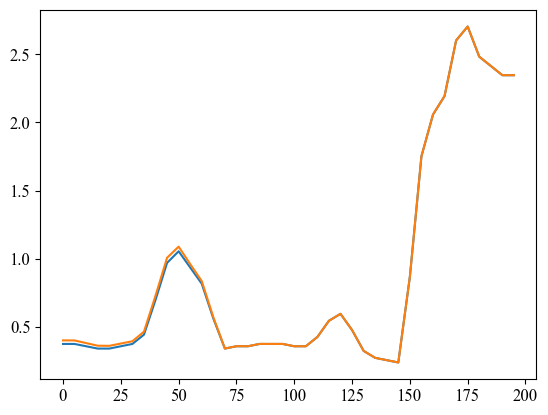

In [10]:
# no skipping

dy = np.gradient(displacement_final)
dy_corrected = np.gradient(displacement_corrected_final)
dt = np.gradient(time_final)
ivel_noskipping = dy/dt
ivel_corrected_noskipping = dy_corrected/dt

fig, ax = plt.subplots()
ax.plot(time_final, ivel_noskipping)
ax.plot(time_final, ivel_corrected_noskipping)
plt.show()

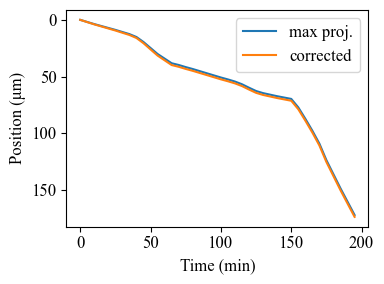

In [11]:
fig, ax = plt.subplots(figsize=[4,3])
ax.plot(time_final, displacement_final, color='tab:blue', label='max proj.')
ax.plot(time_final, displacement_corrected_final, color='tab:orange', label='corrected')
ax.invert_yaxis()
ax.set_xlabel('Time (min)')
ax.set_ylabel('Position (\u03BCm)')
ax.legend()
plt.tight_layout()
plt.savefig('displacement_wo_colors.pdf')

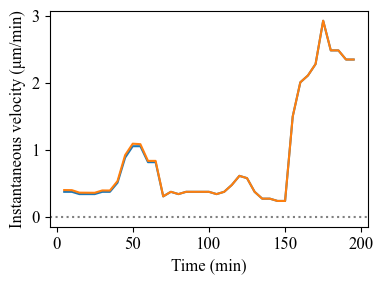

In [12]:
fig, ax1 = plt.subplots(figsize=[4,3])
ax1.plot(ivel_time, ivel)
ax1.plot(ivel_time, ivel_corrected)
ax1.axhline(y=0, ls=':', color='grey')
ax1.set_xlabel('Time (min)')
ax1.set_ylabel('Instantaneous velocity (\u03BCm/min)')
plt.tight_layout()
plt.savefig('ivel_skip_every_' + str(i_vel_skip) + '.pdf')
plt.show()

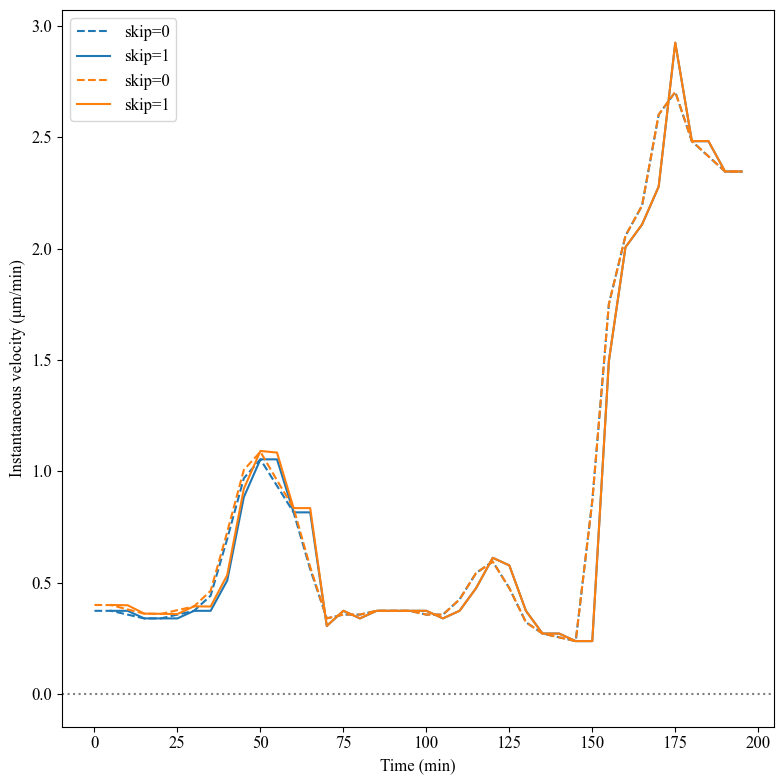

In [13]:
fig, ax1 = plt.subplots(figsize=[8,8])
ax1.plot(time_final, ivel_noskipping, label='skip=0', ls='--', color='tab:blue')
ax1.plot(ivel_time, ivel, label='skip=' + str(i_vel_skip), color='tab:blue')

ax1.plot(time_final, ivel_corrected_noskipping, label='skip=0', ls='--', color='tab:orange')
ax1.plot(ivel_time, ivel_corrected, label='skip=' + str(i_vel_skip), color='tab:orange')

ax1.axhline(y=0, ls=':', color='grey')
ax1.set_xlabel('Time (min)')
ax1.set_ylabel('Instantaneous velocity (\u03BCm/min)')
plt.tight_layout()
plt.legend()
plt.show()

In [14]:
if time_window_to_calculate_variance != 0:
    variance_time_start, variance_time_end = time_window_to_calculate_variance
    variance_range = np.logical_and(ivel_time>variance_time_start, ivel_time<variance_time_end)
else:
    variance_time_start, variance_time_end = ivel_time[0], ivel_time[-1]
    variance_range = ivel_time>=0

print('frames', np.where(variance_range))
variance = np.std(ivel[variance_range])**2
variance_corrected = np.std(ivel_corrected[variance_range])**2

# np.savetxt('var.txt', [variance, variance_time_start, variance_time_end])
print('variance', variance)
print('variance_corrected', variance_corrected)

variance_to_export = pd.DataFrame({'variance': [variance],
                                   'variance_corrected': [variance_corrected],
                                   'start_time': [variance_time_start], 'end_time':[variance_time_end]})
variance_to_export.to_excel('variance_to_export.xlsx')
variance_to_export

frames (array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38]),)
variance 0.6517438316896781
variance_corrected 0.6481101185230943


,variance,variance_corrected,start_time,end_time
0,0.651744,0.64811,5.0,195.0


In [15]:
print('Done! Hooray!')

Done! Hooray!
